# Semana 2 · Laboratorio 1: YOLO + ByteTrack · escenario Nodo
**Maestría en Inteligencia Artificial · Visión Artificial**  
**Referencia:** repositorio `eugeniomorocho/ComputerVision`, unidad `UC.06 Tracking & Video Análisis`, notebook `1. Tracking.ipynb`.

**Objetivos:** (1) detectar y seguir vehículos; (2) seguir exclusivamente personas; (3) visualizar trayectorias; (4) generar un mapa de actividad; (5) contar cruces de una línea virtual.


## 0 · Configurar el entorno
Funciona en **Google Colab**, **Windows** y **macOS**. En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución**, elegir **GPU T4** si está disponible. También funciona en CPU, más lento. Ejecutar las celdas en orden.

**Compatibilidad:** se fija OpenCV 4.11. La reproducción usa FFmpeg del sistema o, si no está instalado, el binario de `imageio-ffmpeg` (sirve en Windows y macOS sin instalar FFmpeg aparte). Si el entorno pide reiniciar tras instalar, reinicia y ejecuta de nuevo desde la celda de importaciones.


In [1]:
# Instalamos YOLO (Ultralytics), el asociador LAP y OpenCV para procesar imágenes y videos.
# En Colab, %pip instala paquetes en el entorno del notebook.
%pip -q install -U ultralytics "lap>=0.5.12" "opencv-python-headless==4.11.0.86" "imageio-ffmpeg>=0.5.1"



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Importamos herramientas para video (OpenCV), IA (PyTorch/YOLO), descargas y manejo de archivos.
import cv2, torch, requests, subprocess, time, os, platform, shutil
import numpy as np
from pathlib import Path
from collections import defaultdict, deque
from IPython.display import Video, display
from ultralytics import YOLO

# En Colab trabajamos en /content; fuera de Colab usamos la carpeta actual.
ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'vision_semana2'
OUT.mkdir(parents=True, exist_ok=True)
# Elegimos GPU CUDA si está disponible; en caso contrario, CPU.
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('OpenCV:', cv2.__version__, '| PyTorch:', torch.__version__)
print('Dispositivo:', torch.cuda.get_device_name(0) if DEVICE != 'cpu' else 'CPU')

def en_colab():
    # google.colab solo existe dentro de Google Colab.
    try:
        import google.colab
        return True
    except ImportError:
        return False

def ruta_ffmpeg():
    # Colab ya trae FFmpeg. En Windows y macOS usamos el del sistema o el de imageio-ffmpeg.
    encontrado = shutil.which('ffmpeg')
    if encontrado:
        return encontrado
    try:
        import imageio_ffmpeg
    except ImportError as e:
        raise RuntimeError(
            'No hay FFmpeg. Ejecuta la celda de instalación y vuelve a correr esta celda.'
        ) from e
    return imageio_ffmpeg.get_ffmpeg_exe()

def solicitar_archivo(descripcion):
    # Colab abre el selector. En Windows y macOS se pega la ruta del archivo.
    if en_colab():
        from google.colab import files
        print(descripcion)
        subidos = files.upload()
        if not subidos:
            raise RuntimeError('No se proporcionó archivo')
        return str(Path(next(iter(subidos))).resolve())
    print(descripcion)
    print('Pega la ruta completa y presiona Enter.')
    print(r'Windows: C:\Users\tu_usuario\archivo.mp4')
    print('macOS: /Users/tu_usuario/archivo.mp4')
    ruta = input('Ruta: ').strip().strip('"').strip("'")
    if not ruta:
        raise RuntimeError('No se proporcionó archivo')
    origen = Path(ruta).expanduser()
    if not origen.is_file():
        raise FileNotFoundError(f'No existe el archivo: {origen}')
    return str(origen.resolve())

print('Entorno:', 'Google Colab' if en_colab() else f'Local ({platform.system()})')
print('FFmpeg:', ruta_ffmpeg())

# Comprueba que el archivo exista y que OpenCV pueda leer su primer fotograma.
def validar_video(ruta):
    ruta = Path(ruta)
    if not ruta.exists() or ruta.stat().st_size < 1024:
        return False
    cap = cv2.VideoCapture(str(ruta))
    ok, frame = cap.read()
    cap.release()
    return bool(ok and frame is not None)

# Convierte el video a H.264 compatible con el navegador y lo muestra en pantalla.
def reproducir(ruta, ancho=850):
    ruta = Path(ruta)
    destino = OUT / (ruta.stem + '_web.mp4')
    subprocess.run([ruta_ffmpeg(),'-y','-loglevel','error','-i',str(ruta),
                    '-c:v','libx264','-preset','veryfast','-pix_fmt','yuv420p',
                    '-an',str(destino)],check=True)
    display(Video(str(destino),embed=True,width=ancho))
    return destino

# Descarga el archivo en bloques y verifica que sea un video válido.
def descargar(url, destino):
    destino = Path(destino)
    with requests.get(url,stream=True,timeout=90,allow_redirects=True) as r:
        r.raise_for_status()
        with open(destino,'wb') as f:
            for bloque in r.iter_content(chunk_size=1024*1024):
                if bloque: f.write(bloque)
    if not validar_video(destino):
        destino.unlink(missing_ok=True)
        raise ValueError('La descarga no contiene un video reproducible (posible puntero Git LFS).')
    return destino


OpenCV: 4.11.0 | PyTorch: 2.14.1
Dispositivo: CPU
Entorno: Local (Darwin)
FFmpeg: /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/imageio_ffmpeg/binaries/ffmpeg-macos-aarch64-v7.1


## 1 · Video de referencia: vehículos
Se utiliza el archivo `UC.04 Object Detection/race_car.mp4` del repositorio. Es un archivo de video real (no el puntero LFS de `UC.06`). La descarga se valida antes de continuar.

In [3]:
# Descargamos el video de carrera solo si aún no está disponible o no se puede leer.
VIDEO_CARROS = OUT / 'race_car.mp4'
URL_CARROS = 'https://raw.githubusercontent.com/eugeniomorocho/ComputerVision/main/UC.04%20Object%20Detection/race_car.mp4'
if not validar_video(VIDEO_CARROS):
    descargar(URL_CARROS, VIDEO_CARROS)
# OpenCV consulta metadatos: fotogramas totales y fotogramas por segundo (FPS).
cap = cv2.VideoCapture(str(VIDEO_CARROS))
fps = cap.get(cv2.CAP_PROP_FPS); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
print(f'Video vehículos: {total} frames; {fps:.1f} FPS; {total/fps:.1f} s' if fps else 'FPS no disponible')

Video vehículos: 210 frames; 30.0 FPS; 7.0 s


## 2 · Seguimiento de vehículos con YOLO + ByteTrack
Se utiliza el modelo preentrenado `yolo26n.pt`. `persist=True` mantiene el estado del tracker al procesar los frames del video. No es necesario entrenar el modelo.

In [4]:
# Cargamos un YOLO preentrenado: detecta vehículos; ByteTrack les asigna IDs a lo largo del video.
modelo_carros = YOLO('yolo26n.pt')
# Medimos cuánto tarda el seguimiento; conf es el umbral mínimo de confianza.
inicio = time.perf_counter()
res_carros = modelo_carros.track(source=str(VIDEO_CARROS), tracker='bytetrack.yaml',
    persist=True, conf=0.25, imgsz=640, device=DEVICE,
    save=True, show=False, verbose=False,
    project=str(OUT), name='tracking_carrera', exist_ok=True)
segundos = time.perf_counter()-inicio
# Contamos los fotogramas con IDs y los distintos IDs observados (no personas/vehículos únicos garantizados).
ids = set(); con_id = 0
for r in res_carros:
    if r.boxes is not None and r.boxes.id is not None:
        con_id += 1
        ids.update(r.boxes.id.int().cpu().tolist())
print(f'Frames: {len(res_carros)} | Tiempo: {segundos:.1f} s | FPS global: {len(res_carros)/segundos:.1f}')
print(f'Frames con IDs: {con_id} | IDs observados: {len(ids)} (no equivalen necesariamente a objetos únicos)')

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/tracking_carrera
Frames: 210 | Tiempo: 21.5 s | FPS global: 9.8
Frames con IDs: 210 | IDs observados: 4 (no equivalen necesariamente a objetos únicos)


## 3 · Visualizar el video de vehículos
**Corrección respecto a la primera versión:** la ruta de salida se construye de manera absoluta y se busca dentro del directorio real, evitando el error de `runs/detect/...`.

In [5]:
# Localizamos el video anotado que YOLO guardó y lo reproducimos en el notebook.
carpeta_carros = OUT / 'tracking_carrera'
# Buscamos archivos de video y elegimos el modificado más recientemente.
candidatos = sorted((p for p in carpeta_carros.rglob('*') if p.suffix.lower() in ('.mp4','.avi','.mov','.mkv')),
                   key=lambda p:p.stat().st_mtime,reverse=True)
assert candidatos, f'No se encontró video en {carpeta_carros}. Archivos: {list(carpeta_carros.rglob("*"))[:12]}'
print('Salida:',candidatos[0])
reproducir(candidatos[0])

Salida: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/tracking_carrera/race_car.mp4


PosixPath('/Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/race_car_web.mp4')

### Preguntas rápidas
1. ¿Qué diferencia hay entre la etiqueta **car** y el **ID** que asigna ByteTrack?
2. ¿Un mismo vehículo conserva su ID en todo momento?
3. ¿Por qué un ID nuevo no garantiza que haya entrado un objeto nuevo a la escena?

## 4 · Obtener video de personas
**Primera opción:** intentar descargar `store.mp4` del mismo repositorio mediante el servicio de medios de GitHub (los archivos de `UC.06` están gestionados con Git LFS). **No se garantiza** que GitHub permita la descarga anónima de ese recurso. Se valida el contenido para evitar guardar un puntero LFS como si fuera MP4.

**Alternativa segura:** en Colab, subir un MP4 propio/autorizado; en Windows o macOS, indicar la ruta del archivo. Para un contador de entradas, conviene cámara fija, 20–60 segundos, personas cruzando una zona visible y sin cortes de edición. Si el video no muestra cruces, el contador puede permanecer en cero: no es un error.

La siguiente celda intenta la descarga. Si falla, ejecuta la celda de subida.


In [6]:
# Intentamos obtener automáticamente un video con personas para el ejercicio principal.
VIDEO_PERSONAS = OUT / 'store.mp4'
url_store = ('https://media.githubusercontent.com/media/'
             'eugeniomorocho/ComputerVision/main/'
             'UC.06%20Tracking%20%26%20Video%20An%C3%A1lisis/store.mp4')
# Si la descarga falla, el notebook permite subir otro video en la celda siguiente.
if not validar_video(VIDEO_PERSONAS):
    try:
        descargar(url_store, VIDEO_PERSONAS)
        print('Video store.mp4 descargado y validado:', VIDEO_PERSONAS)
    except Exception as e:
        print('No fue posible obtener store.mp4 automáticamente:', type(e).__name__, str(e)[:180])
        print('Usa la siguiente celda para subir un MP4 alternativo.')
else:
    print('Video ya disponible:', VIDEO_PERSONAS)

Video store.mp4 descargado y validado: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/store.mp4


In [7]:
# Alternativa: selector en Colab, o ruta local en Windows y macOS.
# EJECUTAR SOLO SI LA DESCARGA ANTERIOR FALLÓ O SI QUIERES OTRO VIDEO.
if not validar_video(VIDEO_PERSONAS):
    ruta = solicitar_archivo('Selecciona un video MP4 de personas, o pega su ruta.')
    VIDEO_PERSONAS = Path(ruta)
    assert validar_video(VIDEO_PERSONAS), 'El archivo indicado no es un video reproducible.'
print('Video de personas listo:', VIDEO_PERSONAS)


Video de personas listo: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/store.mp4


## 5 · Explorar el video y elegir la línea virtual
**Paso 1 de la tarea:** mostrar **cuatro cuadros separados temporalmente** para conocer las zonas de paso y posibles oclusiones. Luego, inspeccionar una línea virtual horizontal para el conteo.

**Diferencia deliberada:** el mapa de calor acumulará el **centro geométrico de cada caja** (`centro_x`, `centro_y`), tal como propone el autor. El contador seguirá utilizando el punto inferior central de la caja (`pie_y`), más cercano al contacto con el suelo, para representar el cruce de una línea horizontal. Ambas medidas se explicitan para evitar confusiones.

Resolución: 1280x720 | FPS: 30.0 | Frames: 10642 | Línea y=432


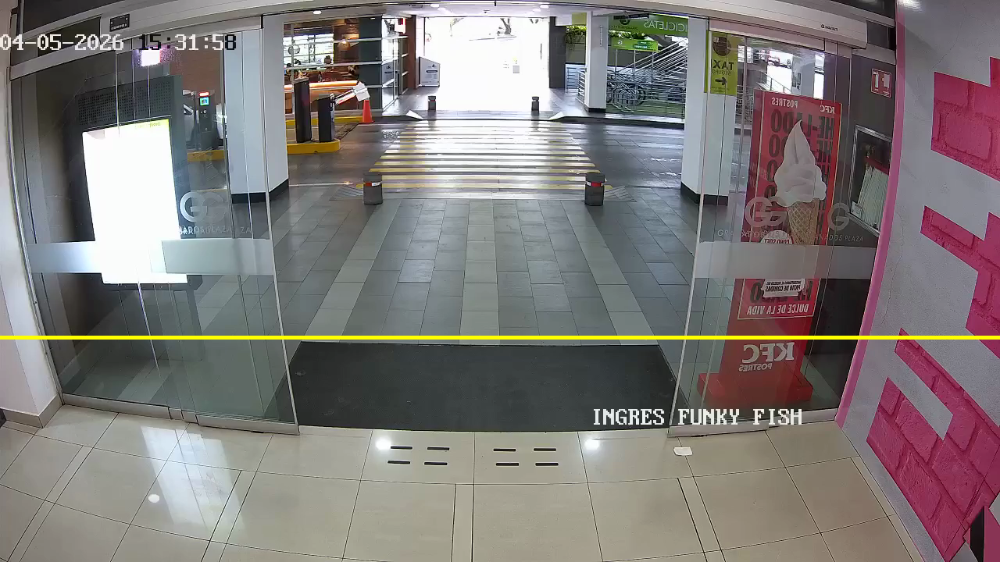

In [8]:
# Leemos un fotograma de muestra y dibujamos una línea virtual para contar cruces.
assert validar_video(VIDEO_PERSONAS), 'Primero descarga o sube un video de personas.'
cap = cv2.VideoCapture(str(VIDEO_PERSONAS))
fps_p = cap.get(cv2.CAP_PROP_FPS) or 25
nframes_p = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.set(cv2.CAP_PROP_POS_FRAMES, max(0,nframes_p//3))
ok, ejemplo = cap.read()
cap.release()
assert ok, 'No se pudo leer el frame de muestra.'
# H y W son alto y ancho en píxeles; la línea se ubica al 60 % de la altura.
H,W = ejemplo.shape[:2]
LINEA_Y_FRACCION = 0.60  # Ajustar visualmente
LINEA_Y = int(H * LINEA_Y_FRACCION)
vista = ejemplo.copy()
cv2.line(vista,(0,LINEA_Y),(W-1,LINEA_Y),(0,255,255),3)
print(f'Resolución: {W}x{H} | FPS: {fps_p:.1f} | Frames: {nframes_p} | Línea y={LINEA_Y}')
from PIL import Image
from IPython.display import display
display(Image.fromarray(cv2.cvtColor(vista,cv2.COLOR_BGR2RGB)))

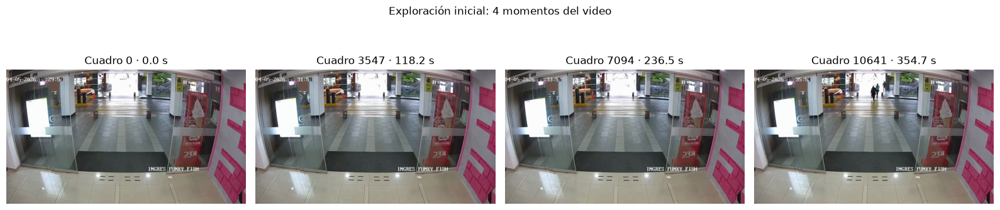

In [9]:
# Extraemos cuatro fotogramas en distintos momentos para conocer la escena antes de analizarla.
# PASO 1: cuatro cuadros espaciados a lo largo del video (exploración inicial)
from matplotlib import pyplot as plt
cap_explorar = cv2.VideoCapture(str(VIDEO_PERSONAS))
total = int(cap_explorar.get(cv2.CAP_PROP_FRAME_COUNT))
assert total > 0, 'No se pudo determinar la longitud del video.'
# Elegimos índices uniformemente repartidos desde el inicio hasta el final.
indices = np.linspace(0, total-1, num=min(4,total), dtype=int)
fig, ejes = plt.subplots(1, len(indices), figsize=(4*len(indices),4))
ejes = np.atleast_1d(ejes)
for ax, idx in zip(ejes,indices):
    cap_explorar.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, cuadro = cap_explorar.read()
    if ok:
        ax.imshow(cv2.cvtColor(cuadro,cv2.COLOR_BGR2RGB))
        ax.set_title(f'Cuadro {idx} · {idx/fps_p:.1f} s')
    else:
        ax.set_title(f'No disponible: {idx}')
    ax.axis('off')
cap_explorar.release()
plt.suptitle('Exploración inicial: 4 momentos del video')
plt.tight_layout();plt.show()


## 6 · Ejercicio integrado: personas + trayectorias + heatmap + contador
**Modelo:** YOLO preentrenado, clase `0` (`person`). **Tracker:** ByteTrack.

- **Trayectorias:** historial reciente del punto inferior-central de cada bounding box, que aproxima el contacto de los pies con el suelo.
- **Heatmap:** acumulación de esas posiciones en una cuadrícula y suavizado gaussiano. Es un **mapa de actividad de detecciones**, no una medida exacta de permanencia ni de personas únicas.
- **Contador:** detecta un cambio de lado respecto de una línea horizontal. Cuenta **una sola vez por ID y por dirección**; puede equivocarse si se pierden o intercambian IDs.

Para que la actividad funcione, la línea debe atravesar una zona con flujo real de personas. El primer frame puede tardar por carga del modelo.

In [10]:
# Pipeline principal: detectar personas, seguir IDs, dibujar trayectorias y contar cruces.
MODELO_PERSONAS = YOLO('yolo26n.pt')
# Parámetros del experimento: límite de fotogramas, confianza y longitud de la trayectoria.
MAX_FRAMES = 900  # Limita la demo a 900 frames; usa None para procesar todo.
CONF = 0.25
MARGEN_CRUCE = max(5, round(H*0.012))  # para reducir conteos por vibración
LARGO_TRAZA = 30

cap = cv2.VideoCapture(str(VIDEO_PERSONAS))
video_salida = OUT / 'personas_analitica.mp4'
writer = cv2.VideoWriter(str(video_salida), cv2.VideoWriter_fourcc(*'mp4v'),
                         fps_p, (W,H))
assert writer.isOpened(), 'No se pudo abrir el archivo de salida.'

# Estructuras para recordar posiciones, lado previo de la línea, IDs contados y mapa de actividad.
historial = defaultdict(lambda: deque(maxlen=LARGO_TRAZA))
ultimo_lado = {}       # -1: arriba, +1: abajo; 0: zona de tolerancia
contados_entrada = set()
contados_salida = set()
entradas = salidas = 0
mapa = np.zeros((H,W),dtype=np.float32)
frames_procesados = 0
ids_vistos = set()
inicio = time.perf_counter()

# Clasifica la posición vertical: arriba (-1), abajo (+1) o franja de tolerancia (0).
def lado(y):
    if y < LINEA_Y - MARGEN_CRUCE: return -1
    if y > LINEA_Y + MARGEN_CRUCE: return 1
    return 0

try:
    while True:
        ok, frame = cap.read()
        if not ok or (MAX_FRAMES is not None and frames_procesados >= MAX_FRAMES):
            break
        # YOLO detecta solo personas (clase 0); ByteTrack conserva sus IDs entre cuadros.
        resultado = MODELO_PERSONAS.track(frame, persist=True, tracker='bytetrack.yaml',
                    classes=[0], conf=CONF, imgsz=640, device=DEVICE, verbose=False)[0]
        salida = frame.copy()
        if resultado.boxes is not None and resultado.boxes.id is not None:
            cajas = resultado.boxes.xyxy.int().cpu().numpy()
            track_ids = resultado.boxes.id.int().cpu().tolist()
            for caja, tid in zip(cajas,track_ids):
                x1,y1,x2,y2 = map(int,caja)
                # Centro de la caja para el mapa de calor; borde inferior para el cruce de línea.
                centro_x = int(np.clip((x1+x2)//2,0,W-1))
                centro_y = int(np.clip((y1+y2)//2,0,H-1))  # CENTROIDE: mapa de calor
                pie_y = int(np.clip(y2,0,H-1))             # PIES: conteo de cruce
                ids_vistos.add(tid)
                historial[tid].append((centro_x,pie_y))
                mapa[centro_y,centro_x] += 1
                cv2.rectangle(salida,(x1,y1),(x2,y2),(0,220,0),2)
                cv2.putText(salida,f'ID {tid}',(x1,max(20,y1-7)),
                            cv2.FONT_HERSHEY_SIMPLEX,0.65,(0,220,0),2)
                puntos = list(historial[tid])
                for k in range(1,len(puntos)):
                    # Puntos antiguos menos intensos; últimos más visibles
                    intensidad = int(60+195*k/max(1,len(puntos)-1))
                    cv2.line(salida,puntos[k-1],puntos[k],(intensidad,50,255),2)
                # Contamos una sola vez por ID y dirección cuando cambia de lado.
                actual = lado(pie_y)
                previo = ultimo_lado.get(tid)
                if actual != 0:
                    if previo == -1 and actual == 1 and tid not in contados_entrada:
                        entradas += 1; contados_entrada.add(tid)
                    elif previo == 1 and actual == -1 and tid not in contados_salida:
                        salidas += 1; contados_salida.add(tid)
                    ultimo_lado[tid] = actual
        cv2.line(salida,(0,LINEA_Y),(W-1,LINEA_Y),(0,255,255),2)
        cv2.putText(salida,f'Arriba->abajo: {entradas} | Abajo->arriba: {salidas}',
                    (12,30),cv2.FONT_HERSHEY_SIMPLEX,0.72,(255,255,255),3)
        cv2.putText(salida,f'Arriba->abajo: {entradas} | Abajo->arriba: {salidas}',
                    (12,30),cv2.FONT_HERSHEY_SIMPLEX,0.72,(0,0,0),1)
        # Guardamos el fotograma anotado en el nuevo video.
        writer.write(salida)
        frames_procesados += 1
# Liberamos cámara/archivo y escritor incluso si ocurre un error.
finally:
    cap.release()
    writer.release()

segundos_personas = time.perf_counter()-inicio
print('Video de salida:',video_salida)
print(f'Frames: {frames_procesados} | Tiempo: {segundos_personas:.1f}s | FPS global: {frames_procesados/segundos_personas:.1f}')
print(f'IDs vistos: {len(ids_vistos)} | Cruces arriba→abajo: {entradas} | abajo→arriba: {salidas}')
print('Atención: los cruces son aproximados y dependen de la línea y de la estabilidad de IDs.')

Video de salida: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/personas_analitica.mp4
Frames: 900 | Tiempo: 41.7s | FPS global: 21.6
IDs vistos: 38 | Cruces arriba→abajo: 2 | abajo→arriba: 1
Atención: los cruces son aproximados y dependen de la línea y de la estabilidad de IDs.


## 7 · Reproducir el video con trayectorias y conteo

In [11]:
# Convertimos y mostramos el video final con cajas, IDs, trayectorias y contadores.
reproducir(video_salida)

PosixPath('/Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/personas_analitica_web.mp4')

## 8 · Construir mapa de calor
Se acumulan centroides de las cajas detectadas en todo el video y se suavizan para visualizar las zonas más transitadas. **No es un mapa calibrado del suelo:** la perspectiva de la cámara distorsiona las distancias; para un análisis métrico habría que calibrar el plano y usar homografía.

Mapa guardado: /Users/jeremyleon/Documents/UIDE/vision-por-computador/semana_2/vision_semana2/mapa_calor_personas.jpg


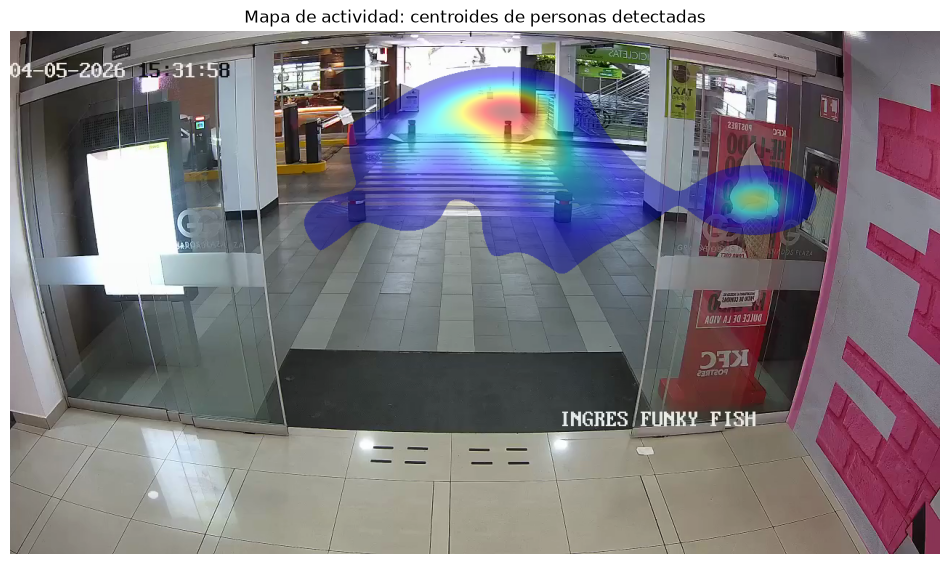

In [12]:
# Convertimos las posiciones acumuladas de personas en un mapa de calor sobre la escena.
from matplotlib import pyplot as plt
# Suavizamos las posiciones acumuladas para visualizar zonas de mayor actividad.
suave = cv2.GaussianBlur(mapa,(0,0),sigmaX=max(8,W/35),sigmaY=max(8,H/35))
if suave.max() > 0:
    normalizado = np.uint8(np.clip(suave/suave.max()*255,0,255))
else:
    normalizado = np.zeros((H,W),dtype=np.uint8)
# Asignamos colores: tonos cálidos indican mayor concentración de detecciones.
colores = cv2.applyColorMap(normalizado,cv2.COLORMAP_JET)
base = ejemplo.copy()
mascara = normalizado > 8
superpuesto = base.copy()
mezcla = cv2.addWeighted(base,0.55,colores,0.45,0)
superpuesto[mascara] = mezcla[mascara]
# Guardamos el mapa sobre una imagen de referencia y lo mostramos.
archivo_heatmap = OUT / 'mapa_calor_personas.jpg'
cv2.imwrite(str(archivo_heatmap),superpuesto)
print('Mapa guardado:',archivo_heatmap)
plt.figure(figsize=(12,7))
plt.imshow(cv2.cvtColor(superpuesto,cv2.COLOR_BGR2RGB))
plt.axis('off'); plt.title('Mapa de actividad: centroides de personas detectadas')
plt.show()

## 9 · Interpretación de resultados (discusión de maestría)
1. ¿Qué zonas presentan mayor actividad? ¿Coinciden con la entrada o con zonas de espera?
2. ¿Qué diferencia existe entre **número de IDs** y **número de personas reales**?
3. ¿Qué ocurre si la línea se mueve o si una persona cruza varias veces?
4. ¿Por qué el mapa de calor no representa directamente ocupación ni tiempo de permanencia?
5. ¿Qué cambiarías para desplegarlo en un coworking real (privacidad, cámaras, iluminación, errores)?

**Experimentación:** modifica `LINEA_Y_FRACCION`, `CONF` o `MAX_FRAMES` y vuelve a ejecutar desde la celda de inspección. Los resultados dependen del video y de la configuración.

**Limitación importante:** el contador de ejemplo utiliza los IDs de ByteTrack; para un sistema de producción se requieren pruebas de oclusión, reingreso, cámara fija, definición formal de zonas, persistencia y métricas contra conteo manual.

## 10 · Registro de limitaciones observadas (Paso 5 de la tarea)
**Completar a partir de los resultados del video utilizado, no con suposiciones.**

| Aspecto | Evidencia observada (cuadro o segundo) | Impacto en los resultados | Posible mejora |
|---|---|---|---|
| Oclusiones (personas que se tapan entre sí) | _Completar_ | _Completar_ | _Completar_ |
| Cambios o pérdidas de ID | _Completar_ | _Completar_ | _Completar_ |
| Falsos positivos o personas omitidas | _Completar_ | _Completar_ | _Completar_ |
| Línea de conteo y perspectiva | _Completar_ | _Completar_ | _Completar_ |

**Preguntas de reflexión:** ¿El mapa representa permanencia o movimiento? ¿Puede un mismo individuo generar más de un ID? ¿Cómo verificarías el conteo con una anotación manual de algunos segundos? ¿Por qué no podemos afirmar que la identidad de una persona es conocida solo por tener un ID de tracking?
